# 04 · Does company type decide which forecast works?

Sessions 1–3 found a different best simple rule for each of three companies: Mattel B1, Caterpillar B0, Alphabet B2. Is that because of the *kind* of company? This session adds 17 companies, so each of four types has five, and tests it.

**Types** were assigned from each business description only, before any results (approved 16 Nov 2026): Seasonal (toys, retail, consumer electronics), Growth tech, Cyclical industrial, FMCG (consumer staples).

**Hypothesis, fixed before evaluating (17 Nov 2026):** the simple rule with the lowest one-quarter-ahead MAPE will be
- Seasonal → **B1** (same quarter last year)
- Growth tech → **B2** (same quarter last year × growth)
- Cyclical industrial → **B0** (last quarter)
- FMCG → **B2** (Penelope's prediction: mild seasonality, steady low growth, price increases 2021–24)

**Main test (fixed):** count the companies whose best simple rule matches their type's prediction, then shuffle the type labels 1,000 times (keeping 5 per type) and see how often a random labelling matches as well.

**Setup** (as in CLAUDE.md, extended for Session 4): fiscal quarters from each company's own fiscal year; the 65-day rule counts from each fiscal quarter's end; the first origin comes after 5 years of each company's own history; first-reported revenue; h = 1–4. Best Buy starts at fiscal 2014 Q1, after its 2012 fiscal-year change. Alphabet is scored without the Motorola targets, as before.

Code: `src/companies.py`, `src/build_quarterly.py`, `src/check_data.py`, `src/evaluate_types.py`. The forecasts were made by `evaluate_types.py run` and saved in `results/session4_forecasts.csv`.

## Setup

In [1]:
from pathlib import Path
import sys, io, contextlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from companies import COMPANIES, TYPES, HYPOTHESIS
from baselines import load
import check_data as cd
from build_quarterly import load_facts, prepare
from evaluate_types import (ALL, load_forecasts, best_rules, placebo, robustness, per_type,
                            ets_vs_best, year_2020)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_colwidth", 80)
q = load(companies=ALL)
with contextlib.redirect_stdout(io.StringIO()):     # build_quarterly prints the values it drops (see section 1)
    facts = prepare(load_facts())
f = load_forecasts()
t = best_rules(f)

## 1. The companies and their data

In [2]:
cov = cd.coverage(q)
cov.insert(1, "why this type", [COMPANIES[c][2] for c in cov.index])
cov

,type,why this type,quarters,first,last,gaps,Q4 reported,Q4 derived,14-week quarters,first origin
company,,,,,,,,,,
Mattel,Seasonal,Toys; most sales ship for the holiday season,74,2008 Q2,2026 Q3,none,10,8,0,2013 Q1
Hasbro,Seasonal,Toys and games; the same holiday-driven calendar,70,2009 Q2,2026 Q3,none,10,7,3,2014 Q1
Williams-Sonoma,Seasonal,Home-furnishings retailer; the holiday quarter is the largest,69,2010 Q2,2027 Q2,none,4,13,3,2015 Q1
Best Buy,Seasonal,Consumer-electronics retailer; the Nov-Jan quarter dominates,54,2014 Q1,2027 Q2,none,5,8,2,2018 Q4
Macy's,Seasonal,Department stores; the holiday quarter dominates,73,2009 Q2,2027 Q2,none,11,7,3,2014 Q1
Alphabet,Growth tech,Online advertising and cloud; revenue has grown most years,74,2008 Q2,2026 Q3,none,0,18,0,2013 Q1
Microsoft,Growth tech,Software and cloud sold increasingly by subscription,77,2008 Q1,2027 Q1,none,13,6,0,2012 Q4
Salesforce,Growth tech,Cloud CRM software sold by subscription,73,2009 Q2,2027 Q2,none,10,8,0,2014 Q1
Netflix,Growth tech,Streaming subscriptions; subscriber-driven growth,74,2008 Q2,2026 Q3,none,10,8,0,2013 Q1


**What this shows:** every company has 54–77 fiscal quarters with no gaps in the series we use. Best Buy starts at fiscal 2014 Q1 (after its 2012 fiscal-year change), so its first forecast origin is fiscal 2018 Q4; the others start between fiscal 2012 Q4 and 2015 Q1. 22 quarters are 14 weeks long (52/53-week companies); they are kept and flagged, not adjusted.

In [3]:
summary, fails = cd.sums_to_year(q, facts)
print("Years whose quarters don't add up to the reported year (within 0.5 %):")
fails[["company", "fiscal_year", "quarters", "year_latest", "q4_direct", "diff_%"]].assign(
    quarters=lambda d: d["quarters"] / 1e9, year_latest=lambda d: d["year_latest"] / 1e9).round(2)

Years whose quarters don't add up to the reported year (within 0.5 %):


,company,fiscal_year,quarters,year_latest,q4_direct,diff_%
0,Alphabet,2012,50.18,46.04,False,8.98
1,Clorox,2009,5.45,5.16,True,5.66
2,Clorox,2012,5.47,5.38,True,1.65
3,General Mills,2009,14.69,14.56,False,0.93
4,Macy's,2017,25.78,25.91,True,-0.50
5,Microsoft,2016,85.32,91.15,True,-6.40
6,Procter & Gamble,2010,78.94,77.57,True,1.77
7,Procter & Gamble,2012,83.68,82.01,True,2.04
8,Procter & Gamble,2013,82.58,73.91,True,11.73
9,Salesforce,2017,8.39,8.44,True,-0.53


In [4]:
cd.revisions(q).join(cd.lags(q))

,revised,over_half_pct,largest_abs_pct,median,max,over 65 days (since 2010)
company,,,,,,
Mattel,5,0,0.47,30.00,75,1
Hasbro,3,0,0.00,38.00,402,1
Williams-Sonoma,0,0,0.00,40.00,424,2
Best Buy,8,8,9.07,34.00,59,0
Macy's,3,1,1.51,37.00,61,0
Alphabet,8,5,7.65,29.00,389,2
Microsoft,4,4,9.81,27.00,34,0
Salesforce,4,2,0.79,31.00,51,0
Netflix,0,0,0.00,22.00,49,0


**What this shows:** in 328 of 338 complete fiscal years the quarters add up to the reported year within 0.5 %. The 10 failures are restatements where a company later restated the full year but not its quarters: discontinued businesses (P&G, Clorox, Alphabet's Motorola) and the 2018 revenue standard (Microsoft, Salesforce, Macy's). The same companies, plus Best Buy, are the only ones whose first-reported and latest revenue differ by more than 0.5 %. That is why forecasts use first-reported revenue. Revenue was public within 22–40 days (median) for every company.

**Flagged jumps:** quarter-to-quarter changes more than 30 % away from the company's usual seasonal change. They are kept in the data, not dropped.

In [5]:
cd.jumps(q).round(2)

,company,type,quarter,period_end,"change vs usual, %",revenue $bn,previous $bn
0,Hasbro,Seasonal,2020 Q1,2020-03-29,40.91,1.11,1.43
1,Hasbro,Seasonal,2020 Q2,2020-06-28,-32.61,0.86,1.11
2,Hasbro,Seasonal,2025 Q1,2025-03-30,46.56,0.89,1.10
3,Macy's,Seasonal,2021 Q1,2020-05-02,-44.40,3.02,8.34
4,Cummins,Cyclical industrial,2020 Q3,2020-09-27,36.13,5.12,3.85
5,PACCAR,Cyclical industrial,2020 Q2,2020-06-30,-43.14,3.06,5.16
6,PACCAR,Cyclical industrial,2020 Q3,2020-09-30,63.01,4.94,3.06
7,Clorox,FMCG,2024 Q2,2023-12-31,49.29,1.99,1.39


**What this shows:** eight quarters moved more than 30 % away from their usual seasonal pattern. Five are the 2020 shock and rebound (Hasbro, Macy's, Cummins, PACCAR). The others are Hasbro buying eOne (end of 2019) and its weak quarter after selling it (2025 Q1), and Clorox's rebound after the August 2023 cyberattack. No acquisition doubled a company, as required.

## 2. Main test: does the type predict the best simple rule?

In [6]:
real, counts = placebo(t)
print(f"Companies whose best simple rule matches their type's prediction: {real} of {len(t)}")
print(f"1,000 random labellings: average {counts.mean():.1f} matches, range {counts.min()}-{counts.max()}")
print(f"Share of random labellings with at least {real} matches: {(counts >= real).mean():.3f}")
pd.Series(counts).value_counts().sort_index().rename("random labellings").to_frame().T

Companies whose best simple rule matches their type's prediction: 13 of 20
1,000 random labellings: average 8.4 matches, range 3-15
Share of random labellings with at least 13 matches: 0.018


,3,4,5,6,7,8,9,10,11,12,13,14,15
random labellings,4,8,42,116,165,192,211,118,102,24,12,2,4


**What this shows:** for 13 of the 20 companies, the best simple rule is the one their type predicted. When the type labels are shuffled at random, labellings match 8.4 companies on average, and only 1.8 % of them match 13 or more. **So the pre-registered main test passes:** company type predicts the best simple rule better than chance (p ≈ 0.02). The placebo works like a lottery check: if random labels did as well as the real ones, the types would tell us nothing.

**Two robustness checks (descriptive):**
1. The hypothesis came from Session 1's results for Mattel, Caterpillar and Alphabet, so those 3 matches were known in advance. What happens with only the 17 new companies?
2. Some "wins" are near-ties. What happens if we keep only companies whose best rule wins by at least 0.5 MAPE points?

In [7]:
robustness(t).round(3)

,companies,matches,shuffled mean,share of shuffles >= real
check,,,,
all 20 (main test),20,13,8.37,0.02
17 new companies only,17,10,7.46,0.11
clear wins only (gap >= 0.5 points),15,10,6.66,0.07


**What this shows:** the result is weaker than the main test suggests. The hypothesis came from Session 1's results for Mattel, Caterpillar and Alphabet, so those three matches were known in advance. On the 17 new companies, 10 match where random labels average 7.5, and 11 % of shuffles do at least as well: **not convincing on its own**. Keeping only clear wins (best rule ahead by at least 0.5 points) gives 10 of 15, p ≈ 0.07. The honest reading: suggestive, not proven.

## 3. One table per type
h = 1 MAPE (%) of each rule and ETS, the best and second-best simple rule, and the gap between them in MAPE points. A small gap means the "win" is close to a tie.

### Seasonal (predicted: B1)

In [8]:
t[t["type"] == "Seasonal"].drop(columns="type").round(2)

baseline,B0,B1,B2,ETS,best,second,gap (points),predicted,match
company,,,,,,,,,
Mattel,44.72,8.89,8.92,7.49,B1,B2,0.03,B1,True
Hasbro,32.02,11.85,10.25,10.14,B2,B1,1.60,B1,False
Williams-Sonoma,18.81,7.15,5.65,3.66,B2,B1,1.50,B1,False
Best Buy,25.62,6.35,6.03,4.07,B2,B1,0.32,B1,False
Macy's,27.78,8.93,8.86,5.25,B2,B1,0.07,B1,False


**What this shows:** the seasonal hypothesis mostly failed. B1 won only for Mattel, and by 0.03 points, a tie. For the other four, B2 (same quarter × growth) won: clearly for Hasbro (eOne) and Williams-Sonoma (strong 2020–21 growth), and only by 0.07–0.32 points for Macy's and Best Buy. Seasonal companies also grow or shrink, so adding recent growth helps a little. B0 is useless here (19–45 %), as expected.

### Growth tech (predicted: B2)

In [9]:
t[t["type"] == "Growth tech"].drop(columns="type").round(2)

baseline,B0,B1,B2,ETS,best,second,gap (points),predicted,match
company,,,,,,,,,
Alphabet,7.51,15.20,5.66,3.41,B2,B0,1.85,B2,True
Microsoft,7.50,11.82,5.68,3.83,B2,B0,1.82,B2,True
Salesforce,4.85,17.65,2.65,2.39,B2,B0,2.20,B2,True
Netflix,4.61,17.17,3.59,2.14,B2,B0,1.01,B2,True
Adobe,3.93,13.23,3.35,2.63,B2,B0,0.58,B2,True


**What this shows:** a clean 5 of 5. B2 wins for every growth company, by 0.6–2.2 points, and B1 is by far the worst (12–18 %) because it ignores growth. B0 comes second: when revenue rises steadily, last quarter is closer than last year.

### Cyclical industrial (predicted: B0)

In [10]:
t[t["type"] == "Cyclical industrial"].drop(columns="type").round(2)

baseline,B0,B1,B2,ETS,best,second,gap (points),predicted,match
company,,,,,,,,,
Caterpillar,7.22,14.07,11.98,5.40,B0,B2,4.76,B0,True
Deere,16.00,13.75,12.73,5.48,B2,B1,1.02,B0,False
Cummins,5.96,10.59,11.14,5.68,B0,B1,4.64,B0,True
PACCAR,7.67,16.05,13.65,8.00,B0,B2,5.98,B0,True
Parker-Hannifin,5.15,7.64,6.97,4.18,B0,B2,1.82,B0,True


**What this shows:** 4 of 5, with clear margins (1.8–6.0 points): for Caterpillar, Cummins, PACCAR and Parker-Hannifin, last quarter beats anything from a year ago. The exception is Deere, where B2 wins and B0 is poor (16 %). As Penelope suspected, Deere is also strongly seasonal: farm machinery sells in spring, so last quarter is the wrong season.

### FMCG (predicted: B2)

In [11]:
t[t["type"] == "FMCG"].drop(columns="type").round(2)

baseline,B0,B1,B2,ETS,best,second,gap (points),predicted,match
company,,,,,,,,,
Procter & Gamble,4.59,4.55,3.35,2.44,B2,B1,1.20,B2,True
Colgate-Palmolive,1.85,4.04,3.08,1.97,B0,B2,1.23,B2,False
Clorox,8.57,6.50,7.77,5.04,B1,B2,1.28,B2,False
Church & Dwight,3.40,5.16,3.22,1.99,B2,B0,0.18,B2,True
General Mills,5.48,4.74,4.34,3.31,B2,B1,0.40,B2,True


**What this shows:** 3 of 5 matches, but two of them (Church & Dwight, General Mills) are near-ties (0.18 and 0.40 points). Colgate-Palmolive is so smooth that "last quarter" wins with the lowest error of all 20 companies (1.85 %), and Clorox picked B1 after its COVID demand surge and 2023 cyberattack. All FMCG errors are small (1.9–8.6 %), so the rules are close together, as Penelope expected.

### All types together

In [12]:
per_type(t).round(2)

,B0,B1,B2,ETS,B0 best,B1 best,B2 best,predicted,matches
type,,,,,,,,,
Seasonal,29.79,8.63,7.94,6.12,0,1,4,B1,1
Growth tech,5.68,15.02,4.19,2.88,0,0,5,B2,5
Cyclical industrial,8.40,12.42,11.29,5.75,4,0,1,B0,4
FMCG,4.78,5.00,4.35,2.95,1,1,3,B2,3


**What this shows:** across types, the clearest pattern is the split between **B0 and B2**. B0 wins 4 of 5 cyclicals and none of the seasonal or growth companies; B2 wins 13 of the 20 companies overall. B1, the classic FP&A rule, won only twice (Mattel, Clorox). ETS has the lowest average error in every type (2.9–6.1 %).

## 4. The summary chart
h = 1 MAPE of B0, B1, B2 and ETS for every company, grouped by type. B0's values for seasonal companies run far off the scale, so they are drawn at the edge with their value.

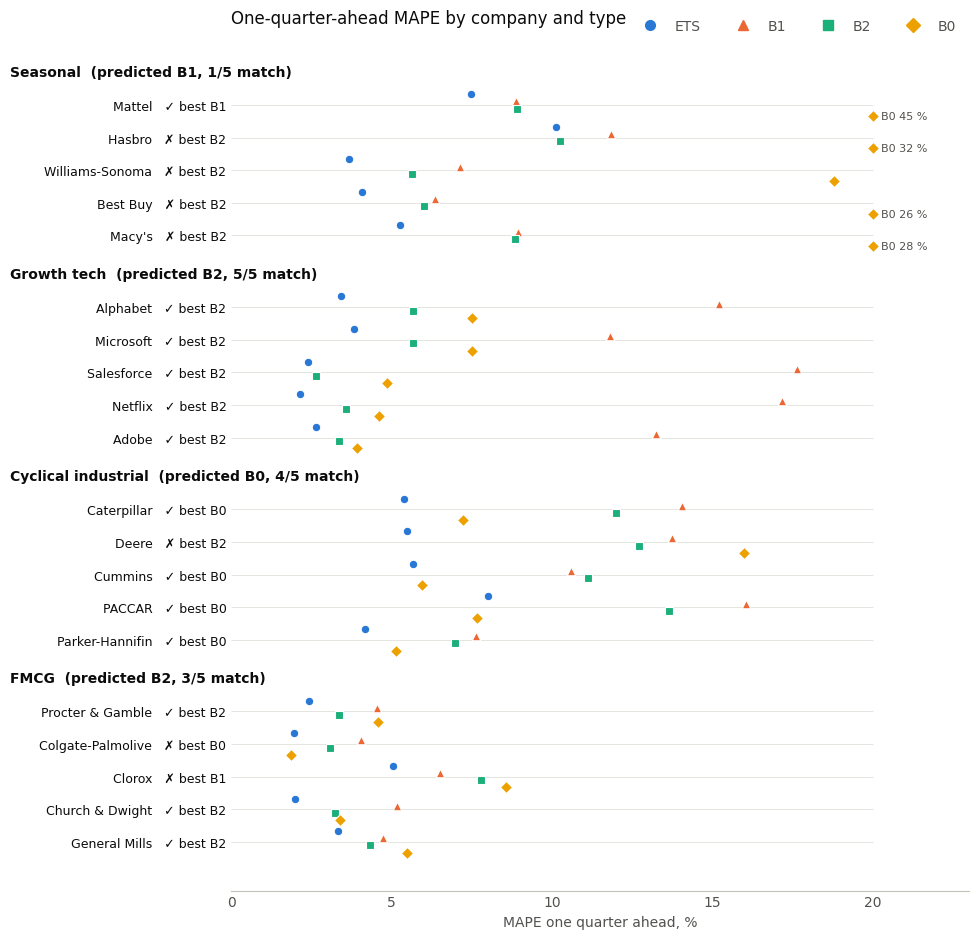

In [13]:
ETSC, B1C, B2C, B0C = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"    # default palette slots 1-4
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
STYLE = {"ETS": (ETSC, "o"), "B1": (B1C, "^"), "B2": (B2C, "s"), "B0": (B0C, "D")}
OFFSET = {"ETS": -0.33, "B1": -0.11, "B2": 0.11, "B0": 0.33}   # small vertical offsets so near-ties stay visible
LIMIT = 20

rows, labels, y = [], [], 0
fig, ax = plt.subplots(figsize=(10, 9.5))
for ty in TYPES:
    for c in [c for c in ALL if t.loc[c, "type"] == ty]:
        rows.append((y, c)); y += 1
    y += 1.2                                             # space between types
for yy, c in rows:
    ax.hlines(yy, 0, LIMIT, color=GRID, lw=0.6, zorder=0)
    for m, (col, mk) in STYLE.items():
        v = t.loc[c, m]
        ax.scatter(min(v, LIMIT), yy + OFFSET[m], color=col, marker=mk, s=38, edgecolor="white", lw=0.8, zorder=3)
        if v > LIMIT:
            ax.text(LIMIT + 0.25, yy + OFFSET[m], f"{m} {v:.0f} %", va="center", fontsize=8, color=MUTED)
    best = t.loc[c, "best"]
    mark = "✓" if t.loc[c, "match"] else "✗"
    labels.append(f"{c}   {mark} best {best}")
ax.set_yticks([r[0] for r in rows], labels, fontsize=9, color=INK)
ax.invert_yaxis()
for ty in TYPES:
    ys = [yy for yy, c in rows if t.loc[c, "type"] == ty]
    ax.text(-0.3, min(ys) - 0.9, f"{ty}  (predicted {HYPOTHESIS[ty]}, {int(t[t['type'] == ty]['match'].sum())}/5 match)",
            transform=ax.get_yaxis_transform(), color=INK, fontsize=10, fontweight="bold", ha="left")
ax.set_xlim(0, LIMIT + 3)
ax.set_xlabel("MAPE one quarter ahead, %", color=MUTED)
ax.tick_params(axis="x", colors=MUTED, length=0)
ax.tick_params(axis="y", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
handles = [plt.Line2D([], [], color=col, marker=mk, ls="", markersize=7, label=m)
           for m, (col, mk) in STYLE.items()]
ax.legend(handles=handles, frameon=False, loc="upper right", bbox_to_anchor=(1, 1.06), ncol=4, labelcolor=MUTED)
ax.set_title("One-quarter-ahead MAPE by company and type", loc="left", color=INK, fontsize=12, pad=24)
fig.tight_layout()
plt.show()

**What this shows:** each row is a company; the markers show how far off each method was one quarter ahead (further left = better). Blue circles (ETS) are leftmost for almost every company. Green squares (B2) beat orange triangles (B1) in most rows, and yellow diamonds (B0) are only competitive for cyclicals, growth companies and FMCG. Where markers sit close together (Mattel, Macy's, Church & Dwight), the "best rule" is effectively a tie.

## 5. ETS vs each company's best simple rule
The best simple rule is the one chosen at h = 1 above. DM p-values are listed for information only: they are not corrected for testing 40 comparisons and are not main results.

In [14]:
e = ets_vs_best(f, t)
e.groupby("test")["ETS wins"].agg(companies="size", ETS_wins="sum")

,companies,ETS_wins
test,,
full year,20,11
h=1,20,18


In [15]:
e.pivot_table(index=["type", "company"], columns="test", values=["MAPE ETS", "MAPE rule", "p"]).round(2).reindex(
    [(ty, c) for ty in TYPES for c in ALL if t.loc[c, "type"] == ty])

MAPE ETS       MAPE rule        \
test                                  full year   h=1 full year   h=1   
type                company                                             
Seasonal            Mattel                 6.93  7.49      6.36  8.89   
                    Hasbro                 9.74 10.14     11.08 10.25   
                    Williams-Sonoma        4.04  3.66      6.69  5.65   
                    Best Buy               4.63  4.07      7.63  6.03   
                    Macy's                 6.10  5.25      9.67  8.86   
Growth tech         Alphabet               5.88  3.41      7.19  5.66   
                    Microsoft              6.44  3.83      6.44  5.68   
                    Salesforce             4.31  2.39      3.04  2.65   
                    Netflix                5.41  2.14      4.31  3.59   
                    Adobe                  5.11  2.63      3.87  3.35   
Cyclical industrial Caterpillar            9.15  5.40      9.23  7.22   
                    Deere                  9.45  5.48     15.96 12.73   
                    Cummins                7.37  5.68      7.25  5.96   
                    PACCAR                12.01  8.00     10.73  7.67   
                    Parker-Hannifin        5.98  4.18      6.25  5.15   
FMCG                Procter & Gamble       3.14  2.44      3.91  3.35   
                    Colgate-Palmolive      2.79  1.97      2.78  1.85   
                    Clorox                 4.41  5.04      3.67  6.50   
                    Church & Dwight        2.37  1.99      3.33  3.22   
                    General Mills          3.61  3.31      4.35  4.34   

                                              p       
test                                  full year  h=1  
type                company                           
Seasonal            Mattel                 0.68 0.25  
                    Hasbro                 0.64 0.93  
                    Williams-Sonoma        0.09 0.01  
                    Best Buy               0.08 0.05  
                    Macy's                 0.18 0.00  
Growth tech         Alphabet               0.60 0.02  
                    Microsoft              1.00 0.01  
                    Salesforce             0.32 0.50  
                    Netflix                0.41 0.00  
                    Adobe                  0.51 0.16  
Cyclical industrial Caterpillar            0.87 0.02  
                    Deere                  0.01 0.00  
                    Cummins                0.61 0.63  
                    PACCAR                 0.50 0.39  
                    Parker-Hannifin        0.15 0.03  
FMCG                Procter & Gamble       0.45 0.03  
                    Colgate-Palmolive      0.93 0.55  
                    Clorox                 0.26 0.16  
                    Church & Dwight        0.13 0.00  
                    General Mills          0.34 0.07

**What this shows:** one quarter ahead, ETS beats each company's best simple rule for 18 of 20 companies (not for PACCAR and Colgate-Palmolive, where B0 is hard to beat). For the full year, it wins only 11 of 20, about a coin flip, just as in Session 2. Several single p-values are small, but with 40 uncorrected comparisons they are listed for information, not as findings.

## 6. The year 2020 by type
h = 1 MAPE for targets whose quarter ended in calendar 2020 vs all other targets (fiscal quarters, so the 2020 quarters differ a little by company).

In [16]:
year_2020(f).round(1)

baseline               B0                B1                B2              \
when                 2020 other years  2020 other years  2020 other years   
type                                                                        
Seasonal            41.10       29.40 17.80        8.00 15.80        7.40   
Growth tech          6.70        5.60 15.60       14.90  4.50        4.10   
Cyclical industrial 17.40        7.70 23.00       11.50 20.70       10.50   
FMCG                 6.50        4.60  9.60        4.60  5.80        4.20   

baseline              ETS              
when                 2020 other years  
type                                   
Seasonal            13.60        5.60  
Growth tech          3.80        2.80  
Cyclical industrial 17.30        4.80  
FMCG                 4.90        2.80

**What this shows:** 2020 hit cyclical companies hardest (ETS 17.3 % vs 4.8 % in other years) and seasonal retailers next (13.6 % vs 5.6 %). FMCG (4.9 % vs 2.8 %) and growth tech (3.8 % vs 2.8 %) were barely disturbed. Every method suffered; ETS stayed best in each type.

## Summary

**Result of the main test:** 13 of 20 companies match their type's predicted rule, against 8.4 for random labels (p ≈ 0.02). **But** three of those matches were known before the hypothesis was written. On the 17 new companies the evidence is weak (10 of 17, p ≈ 0.11), and five "wins" are near-ties.

**What holds up:**
- **Cyclical industrials → last quarter (B0)**, with clear margins, except seasonal Deere.
- **Growth tech → same quarter × growth (B2)**, 5 of 5.
- **Seasonal companies do *not* favour plain "same quarter last year"**: B2 ties or beats it, because they grow too.
- **FMCG:** the rules are so close that the winner is close to luck.

**ETS** beats the best simple rule one quarter ahead for 18 of 20 companies, but for the full year only 11 of 20. That repeats Sessions 2–3: a better next-quarter forecast is not a better full-year forecast.

**For an FP&A team:** with only simple rules, use last quarter for cyclical businesses and same quarter last year × recent growth for almost everyone else.